# Phase 2 — Normalization Rules + Multi-Key Blocking Check

**Purpose.** Phase 1 accepted four name rules. Phase 2 tests the *remaining* candidates
(accent strip, address rules), measures how well name/address **blocking keys** recover true
matches (and what they cost in candidate volume), applies the accepted rules, and re-checks the
feature gaps after normalization.

**Discipline.**
- Everything here uses **train entities only** (`train_s1_ids.txt`, `train_ground_truth.tsv`).
  `val_ground_truth.tsv` is never opened.
- Rules are accepted by a *numeric criterion printed in the notebook*, not by eye.
- The accepted set is written to `normalization_config.json`; later phases import `normalization_v2`.
- Everything is bounded to a sample (≈12k train entities + a 2 % distractor pool) so it runs on a laptop.

**Cross-check against Phase 1.** Phase 1 scored rules on `name_edit_sim` only, against *random* non-matches, with 4,000 pairs.
Section 2b re-tests all Phase 1 name decisions on ~44k true pairs, against *hard* negatives, using all three name features.

**Sections:** 1 Load + sample → 2 Accent-strip test → 2b Re-validate Phase 1 name rules → 3 Address rules → 4 Multi-key union recall →
5 Precision vs volume → 6 Apply normalization → 7 Post-normalization gap re-check → 8 Summary

In [1]:
import os, sys, re, time, pickle, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rapidfuzz import fuzz
from sklearn.feature_extraction.text import TfidfVectorizer
import jellyfish

warnings.filterwarnings("ignore")
sys.path.insert(0, os.getcwd())
import normalization_v2 as nv

ROOT = "../../../"
TRAIN_DIR = ROOT + "dataset/train"
SPLIT_DIR = ROOT + "dataset/split"
INTERIM = ROOT + "dataset/interim"
os.makedirs(INTERIM, exist_ok=True)

SEED = 42
N_ENT = 12_000            # train entities (with >=1 match) in the evaluation sample
N_S1_POP = 100_000        # train S1 records for key-volume estimation
DISTRACTOR_FRAC = 0.02    # fraction of S2/S3 rows kept as distractor pool
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 100
print("setup ok")

setup ok


## 1. Load train-only scope and build the evaluation sample

- **True pairs:** S1 entity ↔ each matched S2/S3 record (from train ground truth).
- **Distractor pool:** a random 2 % of S2/S3 rows (excluding sampled true matches) — used to draw
  *hard negatives* (same name-block as the S1 record) and for key-volume estimates.
- The S2/S3 files are streamed in chunks, once. The sample is cached so re-runs are instant.

In [2]:
train_ids = set(open(SPLIT_DIR + "/train_s1_ids.txt").read().split())
val_ids = set(open(SPLIT_DIR + "/val_s1_ids.txt").read().split())
assert train_ids.isdisjoint(val_ids)

gt = pd.read_csv(SPLIT_DIR + "/train_ground_truth.tsv", sep="\t", dtype=str, keep_default_na=False)
assert set(gt["source1_entity_id"]) <= train_ids, "ground truth contains non-train entities!"
print(f"train ground-truth rows: {len(gt):,}  (all inside train ids: True)")

CACHE = INTERIM + "/phase2_sample.pkl"
if os.path.exists(CACHE):
    with open(CACHE, "rb") as f:
        S = pickle.load(f)
    print("loaded cached sample")
else:
    t0 = time.time()
    s1 = pd.read_csv(TRAIN_DIR + "/train_source1.tsv", sep="\t", dtype=str, keep_default_na=False)
    s1 = s1[s1["entity_id"].isin(train_ids)].reset_index(drop=True)
    n_s1_train = len(s1)

    gt_pos = gt[gt["matched_entity_ids"] != ""]
    samp = gt_pos.sample(N_ENT, random_state=SEED)
    ex = samp.assign(m_id=samp["matched_entity_ids"].str.split(",")).explode("m_id")
    wanted = set(ex["m_id"])

    def scan(path, wanted, frac, seed):
        r = np.random.default_rng(seed)
        hits, dist, total = [], [], 0
        for ch in pd.read_csv(path, sep="\t", dtype=str, keep_default_na=False, chunksize=500_000):
            total += len(ch)
            m = ch["entity_id"].isin(wanted)
            hits.append(ch[m])
            dist.append(ch[(~m) & (r.random(len(ch)) < frac)])
        return pd.concat(hits), pd.concat(dist), total

    h2, d2, t2 = scan(TRAIN_DIR + "/train_source2.tsv", wanted, DISTRACTOR_FRAC, SEED)
    h3, d3, t3 = scan(TRAIN_DIR + "/train_source3.tsv", wanted, DISTRACTOR_FRAC, SEED + 1)

    ren = {"entity_id": "m_id", "business_name": "m_name", "business_address": "m_addr", "country": "m_country"}
    m_all = pd.concat([h2, h3]).rename(columns=ren)
    s1r = s1.rename(columns={"entity_id": "source1_entity_id", "business_name": "s1_name",
                             "business_address": "s1_addr", "country": "country"})
    tp = ex[["source1_entity_id", "m_id"]].merge(s1r, on="source1_entity_id").merge(m_all, on="m_id")
    pool = pd.concat([d2, d3]).rename(columns=ren).reset_index(drop=True)
    pop = s1.sample(N_S1_POP, random_state=SEED).reset_index(drop=True)
    S = dict(tp=tp, pool=pool, pop=pop, n_wanted=len(wanted), n_found=len(m_all),
             n_s1_train=n_s1_train, n_s23_total=t2 + t3)
    with open(CACHE, "wb") as f:
        pickle.dump(S, f)
    print(f"sample built in {time.time()-t0:.0f}s")

tp, pool, pop = S["tp"], S["pool"], S["pop"]
print(f"entities sampled: {tp['source1_entity_id'].nunique():,} | true pairs: {len(tp):,} | "
      f"GT ids requested/found: {S['n_wanted']:,}/{S['n_found']:,}")
print(f"distractor pool: {len(pool):,} of {S['n_s23_total']:,} S2+S3 rows | S1 train rows: {S['n_s1_train']:,}")
assert set(tp["source1_entity_id"]) <= train_ids
tp.head(3)

train ground-truth rows: 1,765,456  (all inside train ids: True)
loaded cached sample
entities sampled: 12,000 | true pairs: 43,946 | GT ids requested/found: 43,946/43,946
distractor pool: 205,478 of 10,320,219 S2+S3 rows | S1 train rows: 1,765,456


,source1_entity_id,m_id,s1_name,s1_addr,country,m_name,m_addr,m_country
0,S1-374982358,S2-796514313,Jkp (India) Land Private Limited,"C/O Panchanan Ghosh, Mouza-Narayanpur Khal Par...",India,Jkp (India) Land Private,"NO. 00727 C/O PANCHANAN GHOSH, MOUZA-NARAYANPU...",India
1,S1-374982358,S3-642074003,Jkp (India) Land Private Limited,"C/O Panchanan Ghosh, Mouza-Narayanpur Khal Par...",India,JL,"C/O Panchanan Ghosh, Mouza-Narayanpur Khal Par...",India
2,S1-614912678,S2-89659532,South Chadwick LLC,"709 E Bear Dr, Tiffin, IA",US,SOUTH CHADWICK LLC,"E BEAR DR, TIFFIN CITY, IA",US


### 1b. Evaluation set: true pairs + hard negatives + random negatives

- **Hard negative** = S1 record paired with a random pool record that shares its *name block*
  (first-4-chars + country, on accent-stripped names). This is the kind of non-match the classifier
  will actually face after blocking.
- **Random negative** = S1 record paired with a random same-country pool record (easy; reported as a secondary view).
- Negatives are drawn **once** and frozen, so every rule variant is scored on identical pairs.

In [3]:
rng = np.random.default_rng(SEED)
ALL_NAME = list(nv.NAME_ORDER)

def blk_key(name, country):
    n = re.sub(r"[^a-z0-9]", "", nv.normalize_name(name, rules=ALL_NAME))
    return n[:4] + "_" + country

pool["blk"] = [blk_key(n, c) for n, c in zip(pool["m_name"], pool["m_country"])]
groups = pool.groupby("blk").indices
tp["blk"] = [blk_key(n, c) for n, c in zip(tp["s1_name"], tp["country"])]

hard_idx, hard_rows = [], []
for i, k in enumerate(tp["blk"].values):
    g = groups.get(k)
    if g is not None and len(g):
        hard_idx.append(i); hard_rows.append(int(rng.choice(g)))
hard = tp.iloc[hard_idx][["source1_entity_id", "s1_name", "s1_addr", "country"]].reset_index(drop=True)
hard = pd.concat([hard, pool.iloc[hard_rows][["m_id", "m_name", "m_addr", "m_country"]].reset_index(drop=True)], axis=1)

rand_rows = []
by_c = {c: np.where(pool["m_country"].values == c)[0] for c in pool["m_country"].unique()}
for c in tp["country"].values:
    rand_rows.append(int(rng.choice(by_c[c])))
rand = tp[["source1_entity_id", "s1_name", "s1_addr", "country"]].reset_index(drop=True)
rand = pd.concat([rand, pool.iloc[rand_rows][["m_id", "m_name", "m_addr", "m_country"]].reset_index(drop=True)], axis=1)

base_cols = ["source1_entity_id", "m_id", "s1_name", "s1_addr", "country", "m_name", "m_addr", "m_country"]
ev = pd.concat([tp[base_cols].assign(label=1, kind="true"),
                hard[base_cols].assign(label=0, kind="hard"),
                rand[base_cols].assign(label=0, kind="rand")], ignore_index=True)
NON_ASCII = re.compile(r"[^\x00-\x7F]")
ev["nonascii"] = ev["s1_name"].str.contains(NON_ASCII) | ev["m_name"].str.contains(NON_ASCII)
print(ev["kind"].value_counts().to_dict(), "| hard-negative coverage of true pairs:",
      f"{len(hard)/len(tp):.1%}")
print("true pairs with non-ASCII name on either side:", f"{ev[(ev.kind=='true')]['nonascii'].mean():.2%}")

# country agreement between S1 and matched record (needed for country-qualified blocking keys)
agree = (tp["country"] == tp["m_country"]).mean()
print(f"true-pair country agreement S1 vs S2/S3: {agree:.4%}")

{'true': 43946, 'rand': 43946, 'hard': 40014} | hard-negative coverage of true pairs: 91.1%
true pairs with non-ASCII name on either side: 14.44%
true-pair country agreement S1 vs S2/S3: 100.0000%


### Feature helpers (same five features as Phase 1) and the gap metric

`gap = median(true) − median(hard negatives)`; `p10_true` = 10th percentile of true-pair scores
(how bad the worst true pairs are — what a threshold has to tolerate).

In [4]:
def toks(s): return set(s.split())

def jacc(a, b):
    sa, sb = toks(a), toks(b)
    if not sa or not sb: return np.nan
    return len(sa & sb) / len(sa | sb)

def tfidf_rowwise(a, b):
    vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=1, dtype=np.float32)
    M = vec.fit_transform(list(a) + list(b)); n = len(a)
    return np.asarray(M[:n].multiply(M[n:]).sum(axis=1)).ravel()

def name_feats(df, fn):
    a = [fn(x) for x in df["s1_name"]]; b = [fn(x) for x in df["m_name"]]
    return pd.DataFrame({
        "name_edit_sim": [fuzz.ratio(x, y) / 100 for x, y in zip(a, b)],
        "name_token_jaccard": [jacc(x, y) for x, y in zip(a, b)],
        "name_tfidf_cosine": tfidf_rowwise(a, b)}, index=df.index)

def addr_feats(df, fn):
    a = [fn(x) for x in df["s1_addr"]]; b = [fn(x) for x in df["m_addr"]]
    both = np.array([bool(x.strip()) and bool(y.strip()) for x, y in zip(a, b)])
    e = np.array([fuzz.ratio(x, y) / 100 for x, y in zip(a, b)], dtype=float)
    j = np.array([jacc(x, y) for x, y in zip(a, b)], dtype=float)
    e[~both] = np.nan; j[~both] = np.nan
    return pd.DataFrame({"addr_edit_sim": e, "addr_token_jaccard": j}, index=df.index)

def gap_table(F, cols, mask_true=None):
    rows = []
    for c in cols:
        t = F.loc[(F.label == 1) & (mask_true if mask_true is not None else True), c].dropna()
        nh = F.loc[F.kind == "hard", c].dropna()
        nr = F.loc[F.kind == "rand", c].dropna()
        rows.append(dict(feature=c, true_med=t.median(), hard_med=nh.median(),
                         gap_hard=t.median() - nh.median(), gap_rand=t.median() - nr.median(),
                         p10_true=t.quantile(0.10), n_true=len(t)))
    return pd.DataFrame(rows).set_index("feature")

NAME_COLS = ["name_edit_sim", "name_token_jaccard", "name_tfidf_cosine"]
ADDR_COLS = ["addr_edit_sim", "addr_token_jaccard"]

## 2. Accent-strip rule test (names)

**Question:** does transliterating non-Latin / accented characters (`unidecode`) raise name similarity of true
pairs, without hurting anything else?

**Accept rule (printed below):**
1. On true pairs with non-ASCII names, `name_tfidf_cosine` median rises by ≥ 0.01, **and**
2. overall `name_tfidf_cosine` gap (true − hard-neg) does not drop by more than 0.002.

features computed in 18s
true pairs affected (non-ASCII): 6,345 of 43,946


,affected_true_med_before,affected_true_med_after,overall_gap_before,overall_gap_after,affected_delta,overall_gap_delta
feature,,,,,,
name_edit_sim,0.4500,0.7302,0.3629,0.3638,0.2802,0.0009
name_token_jaccard,0.0000,0.1667,0.4333,0.4333,0.1667,0.0000
name_tfidf_cosine,0.1998,0.4042,0.5075,0.5412,0.2044,0.0337


affected-subset tfidf delta = +0.2044 (need >= +0.010) | overall gap delta = +0.0337 (need >= -0.002)
DECISION  accent_strip: ACCEPT


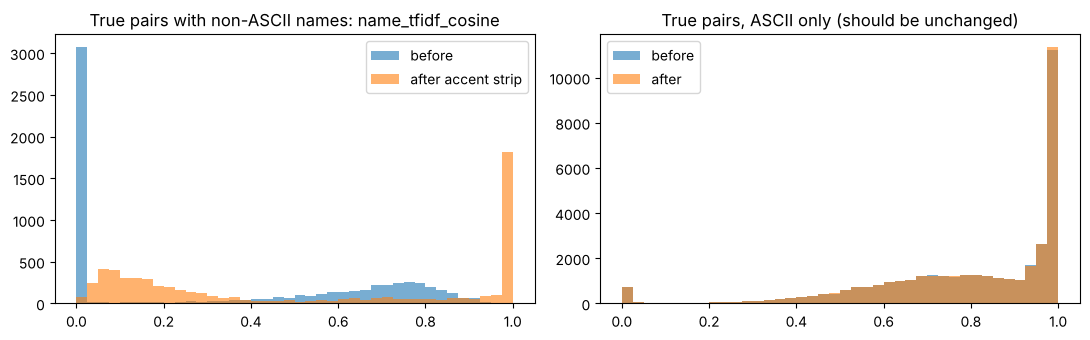

In [5]:
P1 = nv.NAME_PHASE1_ACCEPTED
P1_PLUS = ["accent_strip"] + P1
t0 = time.time()
F_a = pd.concat([ev, name_feats(ev, lambda s: nv.normalize_name(s, rules=P1))], axis=1)
F_b = pd.concat([ev, name_feats(ev, lambda s: nv.normalize_name(s, rules=P1_PLUS))], axis=1)
print(f"features computed in {time.time()-t0:.0f}s")

aff = (F_a.label == 1) & F_a.nonascii
print(f"true pairs affected (non-ASCII): {aff.sum():,} of {(F_a.label==1).sum():,}")
rows = []
for c in NAME_COLS:
    rows.append(dict(feature=c,
        affected_true_med_before=F_a.loc[aff, c].median(), affected_true_med_after=F_b.loc[aff, c].median(),
        overall_gap_before=gap_table(F_a, [c]).loc[c, "gap_hard"], overall_gap_after=gap_table(F_b, [c]).loc[c, "gap_hard"]))
acc = pd.DataFrame(rows).set_index("feature")
acc["affected_delta"] = acc["affected_true_med_after"] - acc["affected_true_med_before"]
acc["overall_gap_delta"] = acc["overall_gap_after"] - acc["overall_gap_before"]
display(acc.round(4))

d_aff = acc.loc["name_tfidf_cosine", "affected_delta"]
d_gap = acc.loc["name_tfidf_cosine", "overall_gap_delta"]
ACCEPT_ACCENT = bool((d_aff >= 0.01) and (d_gap >= -0.002))
print(f"affected-subset tfidf delta = {d_aff:+.4f} (need >= +0.010) | overall gap delta = {d_gap:+.4f} (need >= -0.002)")
print("DECISION  accent_strip:", "ACCEPT" if ACCEPT_ACCENT else "REJECT")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
bins = np.linspace(0, 1, 41)
ax[0].hist(F_a.loc[aff, "name_tfidf_cosine"], bins=bins, alpha=.6, label="before")
ax[0].hist(F_b.loc[aff, "name_tfidf_cosine"], bins=bins, alpha=.6, label="after accent strip")
ax[0].set_title("True pairs with non-ASCII names: name_tfidf_cosine"); ax[0].legend()
nonaff = (F_a.label == 1) & ~F_a.nonascii
ax[1].hist(F_a.loc[nonaff, "name_tfidf_cosine"], bins=bins, alpha=.6, label="before")
ax[1].hist(F_b.loc[nonaff, "name_tfidf_cosine"], bins=bins, alpha=.6, label="after")
ax[1].set_title("True pairs, ASCII only (should be unchanged)"); ax[1].legend()
plt.tight_layout(); plt.show()

## 2b. Re-validate the Phase 1 name rules under hard negatives

Phase 1 accepted `lowercase, whitespace_collapse, suffix_canonicalize, domain_strip` and rejected `punct_strip, ampersand_to_and`.
Those verdicts used edit-similarity and random negatives. Here each verdict is re-checked with
`score = sum of the 3 name-feature gaps (true − negative median)`, computed against **hard** negatives *and* against **random** negatives,
around the current set (accent decision from section 2 + Phase 1 rules):
- **active rule:** removed once; it is **dropped** only if removal does *not* lose ≥ 0.003 under **either** negative type;
- **inactive rule:** added once; it is **added** only if the gain is ≥ 0.003 under **both** negative types.

So a Phase 1 verdict is overturned only when both views agree. Whitespace collapse is structural (cleans up after other rules) and always kept.

In [6]:
def name_scores(rules):
    F = pd.concat([ev, name_feats(ev, lambda s: nv.normalize_name(s, rules=rules))], axis=1)
    g = gap_table(F, NAME_COLS)
    return g["gap_hard"].sum(), g["gap_rand"].sum()

WS = ["whitespace_collapse", "whitespace_final"]
S0 = (["accent_strip"] if ACCEPT_ACCENT else []) + list(nv.NAME_PHASE1_ACCEPTED)
UNITS = {"lowercase": ["lowercase"], "suffix_canonicalize": ["suffix_canonicalize"], "domain_strip": ["domain_strip"],
         "ampersand_to_and": ["ampersand_to_and"], "punct_strip": ["punct_strip"]}
t0 = time.time()
h0, r0 = name_scores(S0)
rows, final = [], list(S0)
for unit, members in UNITS.items():
    active = members[0] in S0
    trial = [r for r in S0 if r not in members] if active else S0 + members
    h, r = name_scores(trial)
    dh, dr = h - h0, r - r0
    if active:
        keep = (dh <= -0.003) or (dr <= -0.003)
        verdict = "KEEP" if keep else "DROP"
        if not keep: final = [x for x in final if x not in members]
    else:
        add = (dh >= 0.003) and (dr >= 0.003)
        verdict = "ADD" if add else "stay out"
        if add: final += members
    rows.append(dict(rule=unit, phase1="accepted" if active else "rejected",
                     d_hard_if_toggled=dh, d_rand_if_toggled=dr, phase2_verdict=verdict))
rv = pd.DataFrame(rows).set_index("rule")
display(rv.round(4))
final = [r for r in nv.NAME_ORDER if r in set(final) | set(WS)]
h1, r1 = name_scores(final)
print(f"score (hard / rand): start set {h0:.4f} / {r0:.4f}  ->  final set {h1:.4f} / {r1:.4f}   [{time.time()-t0:.0f}s]")
print("final name rules:", final)
print("Phase 1 verdicts overturned:", [r for r in rv.index if (rv.loc[r, "phase1"] == "accepted" and rv.loc[r, "phase2_verdict"] == "DROP")
                                       or (rv.loc[r, "phase1"] == "rejected" and rv.loc[r, "phase2_verdict"] == "ADD")] or "none")

,phase1,d_hard_if_toggled,d_rand_if_toggled,phase2_verdict
rule,,,,
lowercase,accepted,-0.0661,-0.1081,KEEP
suffix_canonicalize,accepted,0.0160,-0.0124,KEEP
domain_strip,accepted,-0.0034,-0.0056,KEEP
ampersand_to_and,rejected,-0.0013,0.0004,stay out
punct_strip,rejected,0.1322,0.1636,ADD


score (hard / rand): start set 1.3383 / 1.9855  ->  final set 1.4705 / 2.1490   [62s]
final name rules: ['accent_strip', 'lowercase', 'whitespace_collapse', 'suffix_canonicalize', 'domain_strip', 'punct_strip', 'whitespace_final']
Phase 1 verdicts overturned: ['punct_strip']


## 3. Address rule tests

Candidates (applied in this fixed order): `landmark_strip` → `abbrev_expand` → `punct_strip` → `token_sort`.
Baseline = lowercase + whitespace collapse only. Rules are added **greedily**: a rule is kept only if it improves
`score = gap_edit + gap_jaccard` (hard negatives, pairs where both addresses exist) by ≥ 0.003 on top of the rules already kept.
Each rule is also shown **alone** vs baseline for transparency.

In [7]:
def addr_score(rules):
    F = pd.concat([ev, addr_feats(ev, lambda s: nv.normalize_addr(s, rules=rules))], axis=1)
    g = gap_table(F, ADDR_COLS)
    return g["gap_hard"].sum(), g, F

base_score, base_g, _ = addr_score([])
rows = [dict(variant="baseline (lower+ws)", score=base_score, **{f"gap_{k}": v for k, v in base_g["gap_hard"].items()},
             p10_edit=base_g.loc["addr_edit_sim", "p10_true"])]
for r in nv.ADDR_ORDER:
    s, g, _ = addr_score([r])
    rows.append(dict(variant=f"+ {r} (alone)", score=s, **{f"gap_{k}": v for k, v in g["gap_hard"].items()},
                     p10_edit=g.loc["addr_edit_sim", "p10_true"]))
alone = pd.DataFrame(rows).set_index("variant")
alone["delta_vs_base"] = alone["score"] - base_score
display(alone.round(4))

# greedy forward selection
kept, cur = [], base_score
for r in nv.ADDR_ORDER:
    s, g, _ = addr_score(kept + [r])
    gain = s - cur
    verdict = "ACCEPT" if gain >= 0.003 else "REJECT"
    print(f"{r:15s} gain on top of {kept or ['baseline']}: {gain:+.4f}  -> {verdict}")
    if gain >= 0.003:
        kept.append(r); cur = s
ACCEPT_ADDR = kept
print("\nACCEPTED address rules:", ACCEPT_ADDR)

,score,gap_addr_edit_sim,gap_addr_token_jaccard,p10_edit,delta_vs_base
variant,,,,,
baseline (lower+ws),0.9793,0.4793,0.5000,0.5128,0.0000
+ landmark_strip (alone),0.9780,0.4780,0.5000,0.5136,-0.0013
+ abbrev_expand (alone),1.0722,0.4889,0.5833,0.5227,0.0929
+ punct_strip (alone),1.1200,0.4884,0.6316,0.5195,0.1406
+ token_sort (alone),1.0126,0.5126,0.5000,0.6479,0.0332


landmark_strip  gain on top of ['baseline']: -0.0013  -> REJECT


abbrev_expand   gain on top of ['baseline']: +0.0929  -> ACCEPT


punct_strip     gain on top of ['abbrev_expand']: +0.0931  -> ACCEPT


token_sort      gain on top of ['abbrev_expand', 'punct_strip']: +0.0275  -> ACCEPT

ACCEPTED address rules: ['abbrev_expand', 'punct_strip', 'token_sort']


### 3b. Freeze the decision into the config file
Later phases call `normalization_v2.normalize_name / normalize_addr` and automatically use exactly this set.

In [8]:
ACCEPT_NAME = list(final)
cfg = {"name_rules": ACCEPT_NAME, "addr_rules": ACCEPT_ADDR,
       "criteria": {"accent": "affected tfidf delta>=0.01 and overall gap delta>=-0.002",
                    "addr": "greedy, gain in (gap_edit+gap_jaccard) >= 0.003"}}
with open(nv.CONFIG_PATH, "w") as f:
    json.dump(cfg, f, indent=2)
print(json.dumps(cfg, indent=2))
norm_name = lambda s: nv.normalize_name(s, rules=ACCEPT_NAME)
norm_addr = lambda s: nv.normalize_addr(s, rules=ACCEPT_ADDR)

{
  "name_rules": [
    "accent_strip",
    "lowercase",
    "whitespace_collapse",
    "suffix_canonicalize",
    "domain_strip",
    "punct_strip",
    "whitespace_final"
  ],
  "addr_rules": [
    "abbrev_expand",
    "punct_strip",
    "token_sort"
  ],
  "criteria": {
    "accent": "affected tfidf delta>=0.01 and overall gap delta>=-0.002",
    "addr": "greedy, gain in (gap_edit+gap_jaccard) >= 0.003"
  }
}


## 4. Multi-key blocking: per-key recall and union recall

A blocking key "recovers" a true pair if the S1 record and the matched record produce the **same non-empty key**.
Keys (all country-qualified, built on the *accepted* normalization):

| key | idea |
|---|---|
| `first4` | first 4 alphanumerics of the name |
| `first_token` | first name token |
| `soundex_first` | Soundex of first token (typo-tolerant) |
| `longest_token` | longest name token (robust to leading honorifics / `--` noise) |
| `addr_tail2` | last two comma-separated address parts (city/state area) — works when the name is badly corrupted; empty if address missing |

**Reported:** per-key recall, union recall, greedy marginal gain, and recall on true pairs where an address is missing.

keys built in 1s
true pairs with an address missing on either side: 4.32%
UNION recall (all keys): 94.09% | name keys only: 91.32% | all keys, addr-missing pairs: 99.42%


,recall,recall_when_addr_missing
first4,0.7745,0.9336
first_token,0.7279,0.9446
soundex_first,0.8050,0.9489
longest_token,0.6925,0.8150
addr_tail2,0.2222,0.0000


,key_added,cumulative_recall,marginal_gain
0,soundex_first,0.8050,0.8050
1,longest_token,0.8871,0.0821
2,addr_tail2,0.9205,0.0334
3,first4,0.9409,0.0204
4,first_token,0.9409,0.0000


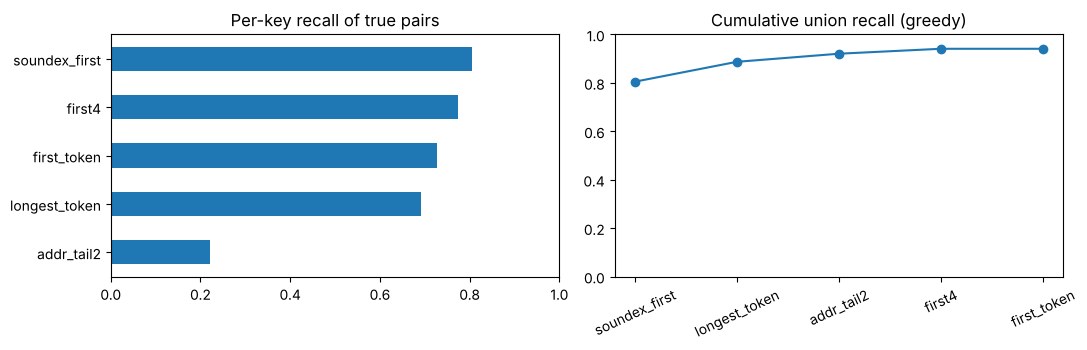


Pairs missed by every key: 2,596 (5.91%). Examples:


,s1_name,m_name,s1_addr,m_addr
13,Shyam International Private Limited,Sri Dovavio,"Door No: 1720, Perunthanni, Ward-84, Thiruvana...","Dsor No: 1720, Thiruvananthapuram, Trivandrum, KL"
20,Eastern Ventures Private Limited,ইস্টার্ন ভেঞ্চারস প্রাইভেট লিমিটেড,"133, Maharshi Debendra Road, Kolkata, Howrah, ...","Kolkata, Maharshi Debendra Road, Howrah, WB, 133"
28,Vigyan Services Private Limited,Caloevo,"Plot No. 30 & 31, Out Of Kh. No. 74/23 Rajinde...","30 & 31, New Delhi, West Delhi, DL"
34,Mumbai Digital,Ariadovamira,"B-4101, Maharashtra, Mumbai City, Mumbai, 41 L...","B-d/4101, 41 Level, India Bulls Blu Tower Dr E..."
36,Arihant Builders Private Limited,Smt ... arihantbuilders.com (ID: 3240),"Pune, Godrez Horizon, Undri Mohamadw Behind Co...","B 1104, PUNE, Maharashtra"
38,Arihant Builders Private Limited,Private Arihant Bhdildres Limited,"Pune, Godrez Horizon, Undri Mohamadw Behind Co...","Plot ##437 B 1104, N/A, Pune, MH"
54,First Management Private Limited,ഫസ്റ്റ് മാനേജ്മെന്റ് പ്രൈവറ്റ് ലിമിറ്റഡ്,"Malappuram, Kerala, Malapuram, Room No. 10/104...","Plot 880 Room No. 10/104/B, Maruthingal, Nilam..."
56,First Management Private Limited,ഫസ്റ്റ് മാനേജ്മെന്റ് പ്രൈവറ്റ് ലിമിറ്റഡ്,"Malappuram, Kerala, Malapuram, Room No. 10/104...","Plot 880 Room No. 10/104/B, Malappuram, Malapu..."


In [9]:
_sx_cache = {}
def sx(t):
    if t not in _sx_cache:
        try: _sx_cache[t] = jellyfish.soundex(t) if t else ""
        except Exception: _sx_cache[t] = ""
    return _sx_cache[t]

def addr_tail2(a):
    parts = [p.strip() for p in a.split(",") if p.strip()]
    return "|".join(parts[-2:]) if parts else ""

def make_keys(names, addrs, countries):
    nn = pd.Series([norm_name(x) for x in names], dtype=object)
    aa = pd.Series([nv.normalize_addr(x, rules=[]) for x in addrs], dtype=object)   # lower+ws, keeps commas
    cc = pd.Series(list(countries), dtype=object)
    tk = nn.str.replace(r"[^a-z0-9\s]", " ", regex=True).str.split()
    ft = tk.str[0].fillna("")
    raw = {
        "first4": nn.str.replace(r"[^a-z0-9]", "", regex=True).str[:4],
        "first_token": ft,
        "soundex_first": ft.map(sx),
        "longest_token": tk.apply(lambda t: max(t, key=len) if isinstance(t, list) and t else ""),
        "addr_tail2": aa.map(addr_tail2),
    }
    out = {}
    for k, v in raw.items():
        out[k] = (v + "_" + cc).where(v != "", None)
    return pd.DataFrame(out)

t0 = time.time()
TP = ev[ev.kind == "true"].reset_index(drop=True)
K1 = make_keys(TP["s1_name"], TP["s1_addr"], TP["country"])
K2 = make_keys(TP["m_name"], TP["m_addr"], TP["m_country"])
print(f"keys built in {time.time()-t0:.0f}s")

KEYS = list(K1.columns)
hit = pd.DataFrame({k: (K1[k].notna() & (K1[k] == K2[k])) for k in KEYS})
missing_addr = (TP["s1_addr"].str.strip() == "") | (TP["m_addr"].str.strip() == "")
print(f"true pairs with an address missing on either side: {missing_addr.mean():.2%}")

per_key = pd.DataFrame({"recall": hit.mean(),
                        "recall_when_addr_missing": hit[missing_addr].mean()})
union_all = hit.any(axis=1)
union_name = hit[[k for k in KEYS if k != "addr_tail2"]].any(axis=1)
print(f"UNION recall (all keys): {union_all.mean():.2%} | name keys only: {union_name.mean():.2%} | "
      f"all keys, addr-missing pairs: {union_all[missing_addr].mean():.2%}")

# greedy marginal ordering
order, cov = [], pd.Series(False, index=hit.index)
rem = list(KEYS)
while rem:
    best = max(rem, key=lambda k: (hit[k] | cov).sum())
    order.append((best, (hit[best] | cov).mean())); cov |= hit[best]; rem.remove(best)
greedy = pd.DataFrame(order, columns=["key_added", "cumulative_recall"])
greedy["marginal_gain"] = greedy["cumulative_recall"].diff().fillna(greedy["cumulative_recall"])
display(per_key.round(4)); display(greedy.round(4))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
per_key["recall"].sort_values().plot.barh(ax=ax[0]); ax[0].set_title("Per-key recall of true pairs"); ax[0].set_xlim(0, 1)
ax[1].plot(range(1, len(greedy) + 1), greedy["cumulative_recall"], marker="o")
ax[1].set_xticks(range(1, len(greedy) + 1)); ax[1].set_xticklabels(greedy["key_added"], rotation=25)
ax[1].set_title("Cumulative union recall (greedy)"); ax[1].set_ylim(0, 1)
plt.tight_layout(); plt.show()

# what the union misses
miss = TP[~union_all].head(8)[["s1_name", "m_name", "s1_addr", "m_addr"]]
print(f"\nPairs missed by every key: {(~union_all).sum():,} ({(~union_all).mean():.2%}). Examples:")
display(miss)

## 5. Precision vs volume trade-off

Recall alone is meaningless without the candidate volume it costs. Estimate for each key (train S1 × all S2/S3):

`volume_k ≈ Σ_key count_S1(key) × count_pool(key) × (S1_train_rows / S1_sample) × (S2S3_rows / pool_rows)`

The two samples are independent, so the product estimator is unbiased (but noisy for very rare keys). The sum over keys
is an **upper bound** for the union (pairs found by several keys are counted more than once).

population keys built in 5s


,recall,est_pairs_billion,recall_per_billion
first4,0.7745,12.6959,0.0610
first_token,0.7279,9.7464,0.0747
soundex_first,0.8050,23.4337,0.0344
longest_token,0.6925,22.7563,0.0304
addr_tail2,0.2222,12.8412,0.0173


Union of all keys: recall 94.09% at <= 81.5 B candidate pairs (upper bound)
Reference — TF-IDF top-20 retrieval (Phase 3, earlier run): recall ~87.75% at 35 M pairs


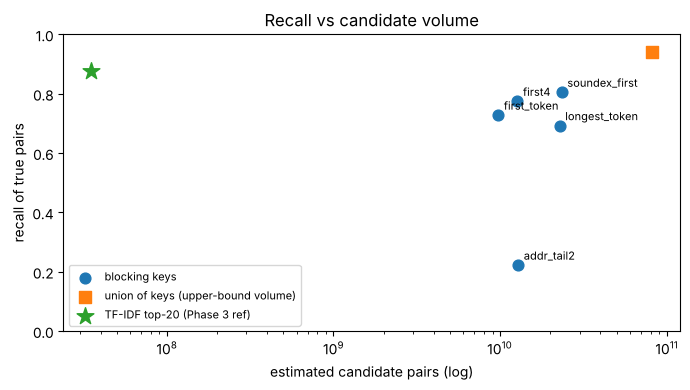

In [10]:
t0 = time.time()
KP = make_keys(pop["business_name"], pop["business_address"], pop["country"])
KQ = make_keys(pool["m_name"], pool["m_addr"], pool["m_country"])
print(f"population keys built in {time.time()-t0:.0f}s")

sc1 = S["n_s1_train"] / len(pop)
sc2 = S["n_s23_total"] / len(pool)
vol = {}
for k in KEYS:
    c1 = KP[k].value_counts(); c2 = KQ[k].value_counts()
    common = c1.index.intersection(c2.index)
    vol[k] = float((c1[common] * c2[common]).sum()) * sc1 * sc2

K_TFIDF = 20
tf_recall = 0.8775           # Phase 3 realistic recall@20 (earlier run, full-scale pool)
tf_volume = K_TFIDF * S["n_s1_train"]
trade = pd.DataFrame({"recall": per_key["recall"], "est_pairs": pd.Series(vol)})
trade["est_pairs_billion"] = trade["est_pairs"] / 1e9
trade["recall_per_billion"] = trade["recall"] / trade["est_pairs_billion"]
display(trade[["recall", "est_pairs_billion", "recall_per_billion"]].round(4))
sum_vol = sum(vol.values())
print(f"Union of all keys: recall {union_all.mean():.2%} at <= {sum_vol/1e9:,.1f} B candidate pairs (upper bound)")
print(f"Reference — TF-IDF top-{K_TFIDF} retrieval (Phase 3, earlier run): recall ~{tf_recall:.2%} at {tf_volume/1e6:,.0f} M pairs")

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(trade["est_pairs"], trade["recall"], s=60, label="blocking keys")
for k, r in trade.iterrows(): ax.annotate(k, (r["est_pairs"], r["recall"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.scatter([sum_vol], [union_all.mean()], marker="s", s=70, label="union of keys (upper-bound volume)")
ax.scatter([tf_volume], [tf_recall], marker="*", s=160, label=f"TF-IDF top-{K_TFIDF} (Phase 3 ref)")
ax.set_xscale("log"); ax.set_xlabel("estimated candidate pairs (log)"); ax.set_ylabel("recall of true pairs"); ax.set_ylim(0, 1)
ax.legend(fontsize=8); ax.set_title("Recall vs candidate volume"); plt.tight_layout(); plt.show()

## 6. Apply normalization (bounded) + sanity checks

Apply the accepted rules to the evaluation sample, the pool and the S1 population sample, and check:
idempotence, no names/addresses destroyed, and share of rows each rule actually changes.
Output is saved to `dataset/interim/phase2_normalized_sample.pkl` (local working file, not part of the zip).

In [11]:
t0 = time.time()
tp_n = tp[["source1_entity_id", "m_id", "country", "m_country"]].copy()
tp_n["s1_name_n"] = [norm_name(x) for x in tp["s1_name"]]; tp_n["m_name_n"] = [norm_name(x) for x in tp["m_name"]]
tp_n["s1_addr_n"] = [norm_addr(x) for x in tp["s1_addr"]]; tp_n["m_addr_n"] = [norm_addr(x) for x in tp["m_addr"]]
pool_n = pool[["m_id", "m_country"]].copy()
pool_n["m_name_n"] = [norm_name(x) for x in pool["m_name"]]; pool_n["m_addr_n"] = [norm_addr(x) for x in pool["m_addr"]]
pop_n = pop[["entity_id", "country"]].copy()
pop_n["name_n"] = [norm_name(x) for x in pop["business_name"]]; pop_n["addr_n"] = [norm_addr(x) for x in pop["business_address"]]
with open(INTERIM + "/phase2_normalized_sample.pkl", "wb") as f:
    pickle.dump(dict(tp=tp_n, pool=pool_n, pop=pop_n, config=cfg), f)
print(f"applied + saved in {time.time()-t0:.0f}s")

# checks
idem_name = np.mean([norm_name(x) == x for x in pop_n["name_n"].head(20000)])
idem_addr = np.mean([norm_addr(x) == x for x in pop_n["addr_n"].head(20000)])
print(f"idempotent (name / addr), 20k check: {idem_name:.4%} / {idem_addr:.4%}")
empt_before = (pop["business_name"].str.strip() == "").sum(); empt_after = (pop_n["name_n"] == "").sum()
print(f"empty names before/after: {empt_before} / {empt_after}")
base_nm = pool["m_name"].map(lambda x: nv.normalize_name(x, rules=nv.NAME_PHASE1_ACCEPTED))
base_ad = pop["business_address"].map(lambda x: nv.normalize_addr(x, rules=[]))
print(f"S2/S3 names changed by the NEW accent rule (beyond Phase 1 rules): {(base_nm != pool_n['m_name_n']).mean():.1%}  (S1 names are Latin, so only S2/S3 are affected)")
print(f"S1 addresses changed by the accepted addr rules (beyond lowercase+ws): {(base_ad != pop_n['addr_n']).mean():.1%}")
ch = pd.DataFrame({"raw": pool["m_name"].head(2000).values, "normalized": pool_n["m_name_n"].head(2000).values})
display(ch[ch.raw != ch.normalized].head(8))
ca = pd.DataFrame({"raw": pool["m_addr"].head(2000).values, "normalized": pool_n["m_addr_n"].head(2000).values})
display(ca[ca.raw.str.lower() != ca.normalized].head(8))

applied + saved in 13s


idempotent (name / addr), 20k check: 100.0000% / 100.0000%
empty names before/after: 0 / 0


S2/S3 names changed by the NEW accent rule (beyond Phase 1 rules): 42.1%  (S1 names are Latin, so only S2/S3 are affected)
S1 addresses changed by the accepted addr rules (beyond lowercase+ws): 100.0%


,raw,normalized
0,શક્તિ અર્બન પ્રોડક્ટ્સ પ્રાઇવેટ લિમિટેડ,shkti arbn proddktts praaivett limittedd
1,United Inc. Defense,united inc defense
2,CHAKRA POWER PRIVATE LIMITED,chakra power pvt ltd
3,Nguyen Studios L.L.C.,nguyen studios l l c
4,Axis Finishers Private Private Limited,axis finishers pvt pvt ltd
5,SOSNOWSKI AND-MITYRE RESEARCH INC,sosnowski and mityre research inc
6,DUDEK INTEGRATED ROCKY LLC,dudek integrated rocky llc
7,ఫార్చూన్ ఇన్ఫోటెక్ ప్రైవేట్ లిమిటెడ్,phaarcuun inphoottek praiveett limittedd


,raw,normalized
0,"SHOP NO.F107 AND F106, FIRST FLOOR SOHAM RESIC...",and f106 f107 first floor gujarat kalali numbe...
1,"563 LAKELAND CIRCLE, ROSHARN CDP, TX",563 cdp circle lakeland rosharn tx
2,"FLAT NO C7-, SEA GATE APARTMENTS, BEHIND MANYA...",4th apartments behind c7 calicut flat gate gat...
3,"1119 KLICKITAT TER, OAK HARBOR, WA",1119 harbor klickitat oak ter wa
4,"ARAZI NO-423, BHANGR PANDA, PANDEYPUR, VARANAS...",423 arazi bhangr number panda pandeypur prades...
5,"Alisdale Drive, TOLEDO, OH",alisdale drive oh toledo
6,"BATON ROUGE, 5940 CYRUS AVE, LA",5940 avenue baton cyrus la rouge
7,"HN 470/2 1-66, MUDINEPALLI, DEVAPUDI, VIJAYAWA...",1 2 470 66 andhra devapudi hn krishna mudinepa...


## 7. Post-normalization gap re-check

Same pairs, same hard negatives as before. Compare **raw strings** vs **final normalization** for all five features.
A feature whose gap *shrinks* after normalization is a red flag (we would have destroyed signal).

,gap_raw,gap_final,true_med_raw,true_med_final,hardneg_med_raw,hardneg_med_final,p10_true_raw,p10_true_final,gap_delta,verdict
feature,,,,,,,,,,
name_edit_sim,0.3457,0.3606,0.8108,0.8889,0.4651,0.5283,0.1754,0.6154,0.0149,ok
name_token_jaccard,0.3750,0.5000,0.5000,0.6667,0.1250,0.1667,0.0000,0.0000,0.1250,ok
name_tfidf_cosine,0.5090,0.6099,0.8122,0.9451,0.3032,0.3352,0.2766,0.3518,0.1009,ok
addr_edit_sim,0.2532,0.5262,0.5316,0.8929,0.2785,0.3667,0.3261,0.6667,0.2730,ok
addr_token_jaccard,0.2500,0.6667,0.2500,0.6667,0.0000,0.0000,0.0714,0.3750,0.4167,ok


recheck done in 24s


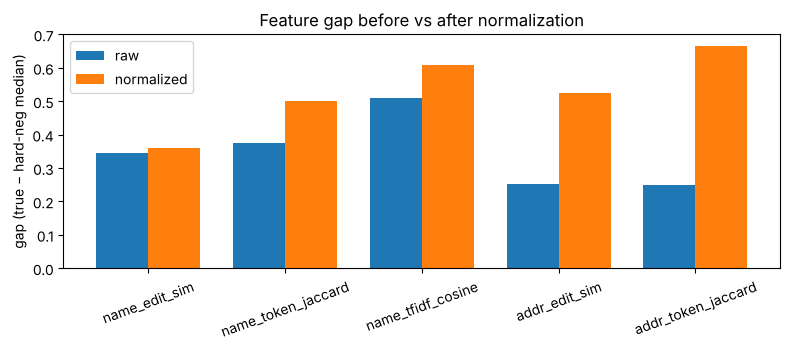

In [12]:
t0 = time.time()
ident = lambda s: str(s)
Fr = pd.concat([ev, name_feats(ev, ident), addr_feats(ev, ident)], axis=1)
Ff = pd.concat([ev, name_feats(ev, norm_name), addr_feats(ev, norm_addr)], axis=1)
ALL_COLS = NAME_COLS + ADDR_COLS
gr, gf = gap_table(Fr, ALL_COLS), gap_table(Ff, ALL_COLS)
cmp = pd.DataFrame({
    "gap_raw": gr["gap_hard"], "gap_final": gf["gap_hard"],
    "true_med_raw": gr["true_med"], "true_med_final": gf["true_med"],
    "hardneg_med_raw": gr["hard_med"], "hardneg_med_final": gf["hard_med"],
    "p10_true_raw": gr["p10_true"], "p10_true_final": gf["p10_true"]})
cmp["gap_delta"] = cmp["gap_final"] - cmp["gap_raw"]
cmp["verdict"] = np.where(cmp["gap_delta"] >= -0.002, "ok", "SIGNAL LOST")
display(cmp.round(4))
print(f"recheck done in {time.time()-t0:.0f}s")

fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(ALL_COLS)); w = 0.38
ax.bar(x - w/2, cmp["gap_raw"], w, label="raw"); ax.bar(x + w/2, cmp["gap_final"], w, label="normalized")
ax.set_xticks(x); ax.set_xticklabels(ALL_COLS, rotation=20); ax.set_ylabel("gap (true − hard-neg median)")
ax.set_title("Feature gap before vs after normalization"); ax.legend(); plt.tight_layout(); plt.show()

## 8. Phase 2 summary and hand-off

In [13]:
print("=== PHASE 2 SUMMARY ===")
print("Accepted name rules :", ACCEPT_NAME)
print("Phase 1 note        : its precision-at-threshold table used RANDOM negatives (precision 1.0 at 0.5 is optimistic) -> do not use it to set thresholds; Phase 8 tunes on realistic candidates.")
print("Accepted addr rules :", ACCEPT_ADDR or "(none beyond lowercase+whitespace)")
print(f"Name-key union recall: {union_name.mean():.2%} | with address key: {union_all.mean():.2%}")
print(f"Upper-bound union volume: {sum_vol/1e9:,.1f} B pairs  vs  TF-IDF top-{K_TFIDF}: {tf_volume/1e6:,.0f} M pairs")
print("Strongest feature after normalization:", cmp["gap_final"].idxmax(), f"(gap {cmp['gap_final'].max():.3f})")
bad = cmp.index[cmp["verdict"] != "ok"].tolist()
print("Features that lost signal:", bad or "none")
print("Config written to:", nv.CONFIG_PATH)
print("Normalized sample :", INTERIM + "/phase2_normalized_sample.pkl")
print("\nHand-off to Phase 3/4: import normalization_v2 (config is picked up automatically). "
      "No validation labels were used in any decision above.")

=== PHASE 2 SUMMARY ===
Accepted name rules : ['accent_strip', 'lowercase', 'whitespace_collapse', 'suffix_canonicalize', 'domain_strip', 'punct_strip', 'whitespace_final']
Phase 1 note        : its precision-at-threshold table used RANDOM negatives (precision 1.0 at 0.5 is optimistic) -> do not use it to set thresholds; Phase 8 tunes on realistic candidates.
Accepted addr rules : ['abbrev_expand', 'punct_strip', 'token_sort']
Name-key union recall: 91.32% | with address key: 94.09%
Upper-bound union volume: 81.5 B pairs  vs  TF-IDF top-20: 35 M pairs
Strongest feature after normalization: addr_token_jaccard (gap 0.667)
Features that lost signal: none
Config written to: /home/claude/business_entity_resolution/code/business_entity_resolution/src/normalization_config.json
Normalized sample : ../../../dataset/interim/phase2_normalized_sample.pkl

Hand-off to Phase 3/4: import normalization_v2 (config is picked up automatically). No validation labels were used in any decision above.
